# Community area regression
Time to completion (mean weekdays per community area) ~ median income + population density + premises with rats.

Run `cleaning-notebook.ipynb` first; it creates `rodent_baiting_clean.gpkg`.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt

from chicago_rat_project import build_community_area_table, run_regression, plot_regression

income_xlsx = "chicagonb-citywide-comparison-economic-median-household-income.xlsx"
density_xlsx = "chicagonb-citywide-comparison-published-tables-population-population-density-people-per-sq-mi.xlsx"

gdf = gpd.read_file("rodent_baiting_clean.gpkg")

## Community area table
One row per community area. `COMMUNITY_AREAS` makes the CSV's area numbers line up with the names in the spreadsheets.

In [2]:
table = build_community_area_table(gdf, income_xlsx, density_xlsx)
print(len(gdf), "records;", len(table), "community areas")
table.head()

293160 records; 77 community areas


,Community Area,Community Area Name,Time to completion,Premises with rats,Reports,Median income,Population density
0,1,Rogers Park,8.649372,2.536684,4934,63087,29485
1,2,West Ridge,8.814202,3.111951,13547,70852,22214
2,3,Uptown,8.088444,2.267041,4093,73919,24148
3,4,Lincoln Square,8.547581,2.246573,4960,92176,16286
4,5,North Center,10.484950,2.077759,5980,147280,17611


## Model

In [3]:
results = run_regression(table)
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:     Time to completion   R-squared:                       0.251
Model:                            OLS   Adj. R-squared:                  0.221
Method:                 Least Squares   F-statistic:                     8.174
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           9.19e-05
Time:                        13:19:59   Log-Likelihood:                -115.39
No. Observations:                  77   AIC:                             238.8
Df Residuals:                      73   BIC:                             248.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


## Partial regression plots
Each panel shows one predictor vs. time to completion with the other two held constant (both axes are residuals, so 0 = average, not a z-score).

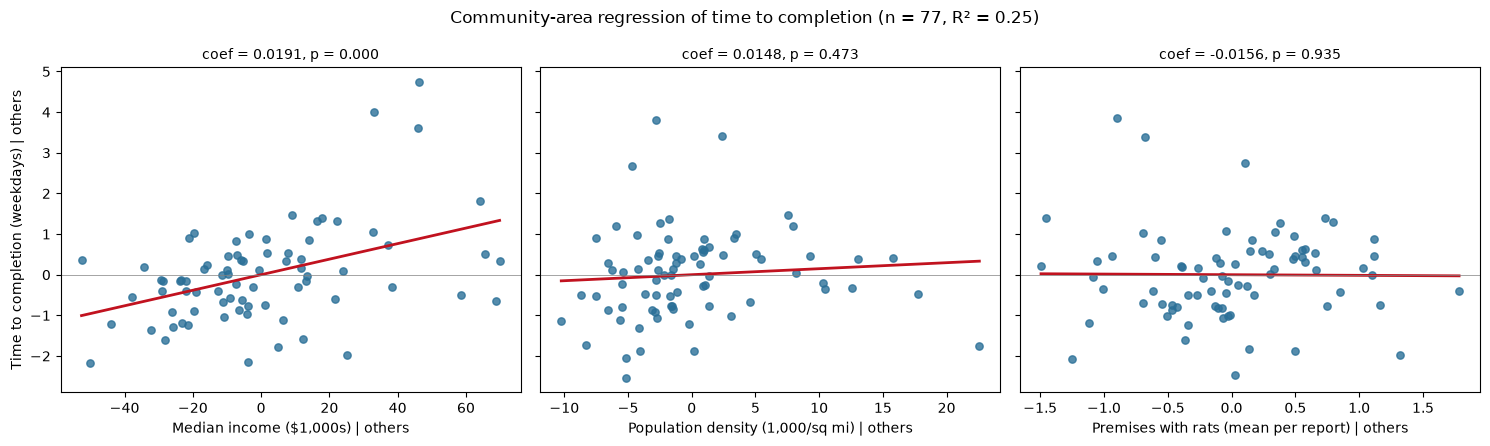

In [4]:
plot_regression(table, results, path="results/regression_plot.png")
plt.show()

## Save results

In [5]:
import os
os.makedirs("results", exist_ok=True)
table.to_csv("results/community_area_table.csv", index=False)
open("results/regression_summary.txt", "w").write(str(results.summary()))

ci = results.conf_int()
ci.columns = ["CI 2.5%", "CI 97.5%"]
coefs = (results.params.rename("coef").to_frame()
         .join(results.bse.rename("std err"))
         .join(results.pvalues.rename("p-value"))
         .join(ci).round(4))
coefs.to_csv("results/regression_coefficients.csv")
coefs

,coef,std err,p-value,CI 2.5%,CI 97.5%
const,6.8631,0.5167,0.0000,5.8333,7.8928
"Median income ($1,000s)",0.0191,0.0047,0.0001,0.0098,0.0284
"Population density (1,000/sq mi)",0.0148,0.0205,0.4733,-0.0261,0.0556
Premises with rats (mean per report),-0.0156,0.1906,0.9352,-0.3954,0.3643
